# *Recurrent Neural Network (RNN)*

In [1]:
# Full code for forward pass + BPTT

import numpy as np
import matplotlib.pyplot as plt

# Step1 - Input
word_vector = {
    "I": ([0.1, 0.2]),
    "Love": ([0.5, 0.7]),
    "NLP": ([0.3, 0.7])
}

sentence = ["I", "Love", "NLP"]
true_label = np.array([0,1])  # Class 1 --> Positive

In [3]:
# Step 2 - RNN parameters

np.random.seed(42)

W_xh = np.array([[0.1, 0.2 ], [0.3, 0.4]])

W_hh = np.array([[0.5, -0.1 ], [0.2, 0.6]])

W_hy = np.array([[0.1, -1.0 ], [-1.0, 1.0]])

b_h = np.zeros(2)

b_y = np.zeros(2)

In [4]:
# Step 3 - Forward Pass

def softmax(x):
  e_x = np.exp(x - np.max(x))
  return e_x / e_x.sum()

h_0 = np.zeros(2)
h_list = [h_0]
x_list = []

In [5]:
# Forward through time

for word in sentence:
  x_t = word_vector[word]
  x_list.append(x_t)
  h_prev= h_list[-1]
  h_t = np.tanh(np.dot(W_xh, x_t) + np.dot(W_hh, h_prev) + b_h)
  h_list.append(h_t)

# Final Prediction
logits = np.dot(W_hy, h_list[-1]) + b_y

y_pred = softmax(logits)
initial_loss = -np.log(y_pred[np.argmax(true_label)])


In [6]:
# BackPropagation through time (BPTT)

d_logits = y_pred - true_label

# Gradient for the output weights

dW_hy = np.outer(d_logits, h_list[-1])
db_y = d_logits.copy()
dh_next = np.dot(W_hy.T, d_logits)

# Initialize the RNN gradients

dW_xh = np.zeros_like(W_xh)
dW_hh = np.zeros_like(W_hh)
db_h = np.zeros_like(b_h)

In [7]:
# BPTT

for t in reversed(range(len(sentence))):
  h_t = h_list[t+1]
  h_prev = h_list[t]
  x_t = x_list[t]

  dz = (1 - h_t**2) # tanh *  dh
  db_h += dz
  dW_xh += np.outer(dz, x_t)
  dW_hh += np.outer(dz, h_prev)

  dh_next = np.dot(W_hh.T, dz)


In [9]:
# Update Weights

learning_rate = 0.1

W_xh -= learning_rate * dW_xh
W_hh -= learning_rate * dW_hh
W_hy -= learning_rate * dW_hy

b_h -= learning_rate * db_h
b_y -= learning_rate * db_y

In [11]:
# Forward Pass after the update

h_0 = np.zeros(2)
h_list = [h_0]
x_list = []

for word in sentence:
  x_t = word_vector[word]
  x_list.append(x_t)
  h_prev = h_list[-1]
  h_t = np.tanh(np.dot(W_xh, x_t) + np.dot(W_hh, h_prev) + b_h)
  h_list.append(h_t)

logits = np.dot(W_hy, h_list[-1]) + b_y
y_pred = softmax(logits)
updated_loss = -np.log(y_pred[np.argmax(true_label)])


In [12]:
print("Loss before update:", round(initial_loss, 4))
print("Loss after update:", round(updated_loss, 4))

Loss before update: 0.3259
Loss after update: 0.6487


In [13]:
gradients = {
    'dW_xh': np.linalg.norm(dW_xh),
    'dW_hh': np.linalg.norm(dW_hh),
    'dW_hy': np.linalg.norm(dW_hy),
    'db_h': np.linalg.norm(db_h),
    'db_y': np.linalg.norm(db_y)

}

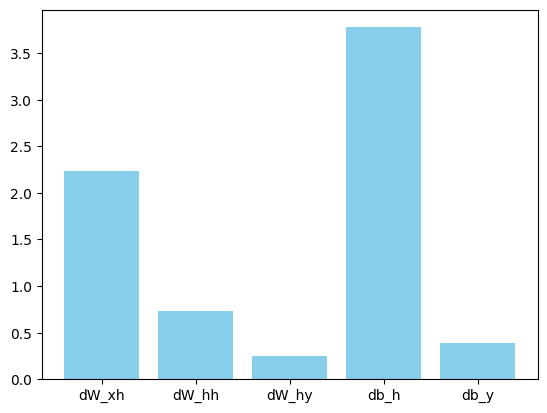

In [14]:
plt.bar(gradients.keys(), gradients.values(), color = 'skyblue')
plt.show()


 # **Sentiment Analysis**

In [16]:
sentences = ['ilove it', 'i hate it', 'so good', 'very bad', 'awesome movie', 'worst ever']
labels = [1, 0, 1, 0, 1, 0]

In [20]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)
x = tokenizer.texts_to_sequences(sentences)
x = pad_sequences(x, padding = 'post')
y = np.array(labels)

vocab_size = len(tokenizer.word_index) + 1

In [21]:
# Build the RNN Model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

model = Sequential([
    Embedding(input_dim = vocab_size, output_dim = 8, input_length = x.shape[1]),
    SimpleRNN(units = 16),
    Dense(units = 1, activation = 'sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [24]:
model.compile(loss= 'binary_crossentropy', optimizer= 'adam', metrics = ['accuracy'])
model.fit(x, y, epochs = 50, verbose=0)

In [25]:
test_sent = ['really good']
test_seq = tokenizer.texts_to_sequences(test_sent)
test_seq = pad_sequences(test_seq, padding = 'post', maxlen = x.shape[1])

prediction = model.predict(test_seq)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 615ms/step
[[0.5642863]]


In [26]:
test_sent = ['ilove it']
test_seq = tokenizer.texts_to_sequences(test_sent)
test_seq = pad_sequences(test_seq, padding = 'post', maxlen = x.shape[1])

prediction = model.predict(test_seq)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
[[0.75501436]]
